In [1]:
# Create functions to find and plot remarkable points

import matplotlib.pyplot as plt
import numpy as np
index =  [    0,    1,    2,    3,    4,    5,    6,    7,    8,    9   ]
signal =  [   -1,    1,    2,    1,    0,   -1,    1,    2,    1,   -2   ]



In [ ]:
# Explain and improve the previous code
def find_zero_crossings_no_zeros(signs: np.ndarray):
    """Find zero crossings in a sign array without zeros"""
    # on veut trouver les passages à 0 en utilisant le changement de signe de la valeur qui permet d'indiquer qu'elle est passée par 0

    diff = np.diff(signs)
    # on calcule la différence entre les élémeents consécutifs pour détecter les changements

    i_cross_pos = np.where(diff > 0)[0]
    # dans le cas où le signe pas de négatif à positif
    i_cross_neg = np.where(diff < 0)[0]
    # dans le cas où le signe passe de positif à négatif
    return i_cross_pos, i_cross_neg


def propagate_signs_over_zeros(signs: np.ndarray):
    """Propagate non-zero signs over zero positions in the sign array."""
    # Les zéros sont remplacés par le signe non nul le plus récent qui les précède. Si des zéros apparaissent avant le premier élément non nul, ils sont remplis par le premier signe non nul suivant.

    signs_no_zeros = signs.copy()

    mask = signs_no_zeros != 0
        # permet d'identifier les éléments non nuls

    idx = np.where(mask, np.arange(len(signs_no_zeros)), 0)
    # création d'un tableau avec les indices des éléments non nuls, et 0 pour les zéros
    idx = np.maximum.accumulate(idx)
    # remplace le 0 par l'élément non nul le plus proche
    signs_no_zeros = signs_no_zeros[idx] # création d'un nouveau tableau prenant en compte les indications ci dessus

    if signs_no_zeros[0] == 0: # si le tableau commence par un zéro, on remplace les zéros initiaux par le premier élément non nul suivant
        i_first_nonzero = np.where(signs != 0)[0]
        if len(i_first_nonzero) > 0:
            signs_no_zeros[: i_first_nonzero[0]] = signs[i_first_nonzero[0]]

    return signs_no_zeros


def find_zero_crossings(s: np.ndarray):
    """Find zero crossings in a 1D signal array."""
    # repère TOUS les passages à zéro dans un tableau

    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    signs = np.sign(s).astype(int)
    # On transforme le signal pour ne garder que les signes : -1, 0 ou 1
    i_zeros = np.where(signs == 0)[0]
    if i_zeros.size > 0:
        signs_no_zeros = propagate_signs_over_zeros(signs)
    else:
        signs_no_zeros = signs

    return find_zero_crossings_no_zeros(signs_no_zeros)

In [ ]:
def test_find_zero_crossings():
    """Unit tests for find_zero_crossings function."""
    # on verifie que la fonctionne fonctionne correctement en testant plusieurs exemples
    
    # Test 1: Pour signal qui alterne entre -1 et 1
    s = np.array([-1, 1, -1, 1, -1])
    # expected     +  -   +  -   +
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([0, 2]))
    assert np.array_equal(i_neg, np.array([1, 3]))


# Test 2 : Pour un signal qui contient des 0
    s = np.array([-1, 0, 0, 1, 0, -1])
    # expected     -     +     -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([2]))
    assert np.array_equal(i_neg, np.array([4]))

 
 
 # Test 3: pour un signal qui n'a que des 0 ou pas de changement de signe
    s = np.array([0, 0, 0, 1, 0, 0])
    # expected    no crossings
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([]))


# Test 4: pour un signa qui a des 0 au début au milieu et à la fin
    s = np.array([0, 0, 1, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))


# Test 5: autre cas avec des 0 et un passage de 1 à -1
    s = np.array([0, 1, 0, 0, -1, 0])
    # expected             -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([3]))


# Test 6 : Un signal qui commence par 1, passe par des zéros, puis va vers -1
    s = np.array([1, 0, 0, -1, 0, 0])
    # expected          -
    i_pos, i_neg = find_zero_crossings(s)
    assert np.array_equal(i_pos, np.array([]))
    assert np.array_equal(i_neg, np.array([2]))


# Testing the function
# on lance tous les test/exemples de cas
try:
    test_find_zero_crossings()
    print("All tests passed.")
except AssertionError:
    raise  # propagate the error, càd indique si un test échoue et si oui lequel

All tests passed.


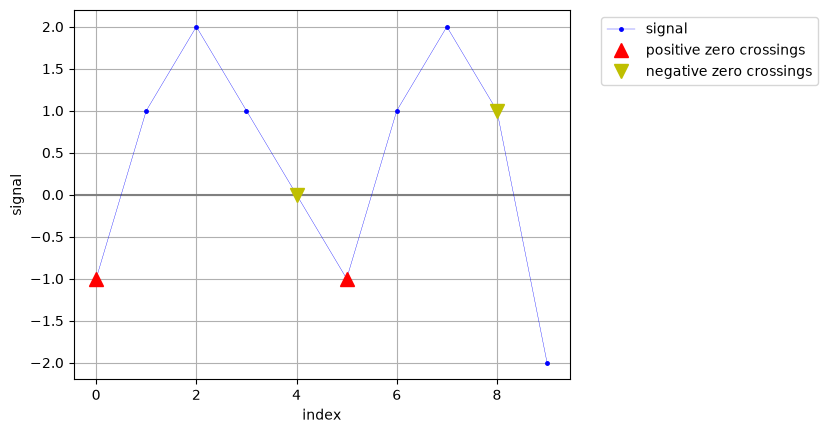

In [9]:
def plot_signal(i: np.ndarray, s: np.ndarray, color: str = "blue"):
    """Plot the signal as function of time/index with grid and zero line"""
    plt.axhline(y=0, color="gray", linestyle="-")  # before to be under the signal
    plt.plot(i, s, ".-", markersize=5, linewidth=0.25, color=color, label="signal")
    plt.ylabel("signal")
    plt.xlabel("index")


def plot_remarkable_points(t: np.ndarray, s: np.ndarray, format: str, label: str):
    """Plot remarkable points on a signal with format and label"""
    plt.plot(t, s, format, markersize=10, label=label)


def plot_positive_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot positive zero crossings on a signal"""
    i_pos, _ = find_zero_crossings(s)
    plot_remarkable_points(i[i_pos], s[i_pos], "^r", "positive zero crossings")


def plot_negative_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot negative zero crossings on a signal"""
    _, i_neg = find_zero_crossings(s)
    plot_remarkable_points(i[i_neg], s[i_neg], "vy", "negative zero crossings")


def plot_zero_crossings(i: np.ndarray, s: np.ndarray):
    """Plot all zero crossings on a signal"""
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)


def display_signal_and_crossings(i: np.ndarray, s: np.ndarray):
    """Plot signal and zero crossings with legend outside the plot and grid"""
    plt.figure()
    plot_signal(i, s)
    plot_positive_zero_crossings(i, s)
    plot_negative_zero_crossings(i, s)
    # NOTE: legend outside does not work well with %matplotlib widget
    plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.grid(True)
    plt.show()


# Example usage
display_signal_and_crossings(np.array(index), np.array(signal))

In [12]:
# Create new functions to find the local maxima a signal
def find_local_maxima(s: np.ndarray):
    """
    Find local maxima in a 1D signal.

    Inputs:
    s = the input signal

    Outputs:
    i_max = indices of local maxima
    """
    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # un maxima local est un point plus grand que les points qui l'entourent
    i_max = np.where((s[1:-1] > s[:-2]) & (s[1:-1] > s[2:]))[0] + 1
    return i_max

In [13]:
# Create new functions to find the local minima of a signal
def find_local_minima(s: np.ndarray):
    """
    Find local minima in a 1D signal.

    Inputs:
    s = the input signal

    Outputs:
    i_min = indices of local minima 
    """
    s = np.asarray(s)
    if s.ndim != 1:
        raise ValueError("Input must be a 1D array")

    # un minima local est un point plus petit que les points qui l'entourent
    i_min = np.where((s[1:-1] < s[:-2]) & (s[1:-1] < s[2:]))[0] + 1
    return i_min

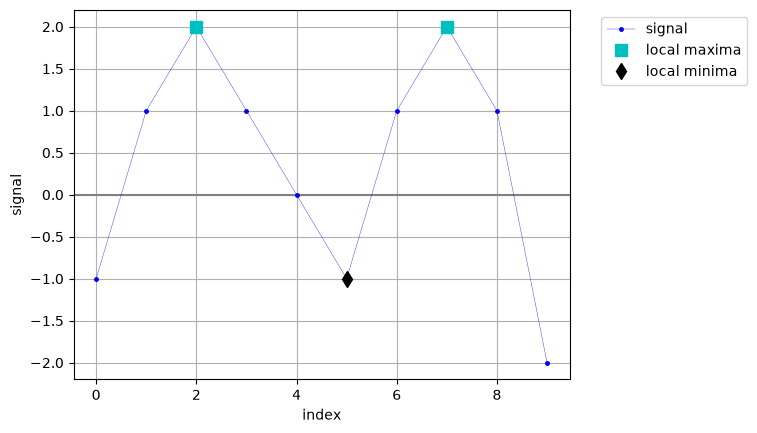

In [16]:
# Est ce que index et signal sont bien des tableaux
i_arr = np.array(index)
s_arr = np.array(signal)

# utilisation de la fonction pour trouver les maxima et minima locaux
i_max = find_local_maxima(s_arr)
i_min = find_local_minima(s_arr)

plt.figure()  # création du graph
plot_signal(i_arr, s_arr)  # tracé du signal

plt.plot(i_arr[i_max], s_arr[i_max], "sc", markersize=8, label="local maxima")  
plt.plot(i_arr[i_min], s_arr[i_min], "dk", markersize=8, label="local minima") 

# affichage de la légende et du quadrillage
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.grid(True)
plt.show()